# Taller 1 · ¿Hasta dónde sirve el modelo del balancín?

**Control Inteligente II (168418) · Universidad de Pamplona**
Docente: Ing. Jeisson Martínez Flórez · Viernes 23 de octubre de 2026

---

Actividad **formativa**, sin nota. Trabaje con su equipo de proyecto.

**Qué va a hacer.** Va a simular el robot balancín que construyeron este semestre. Va a medir en cuánto
tiempo se cae sin control, va a encontrar el polo inestable de la planta y va a determinar hasta qué
ángulo el *modelo linealizado* sigue siendo válido. Esos tres números son importantes para el resto de temas que vamos a ver.

**Requisitos.** Solo `numpy` y `matplotlib`. Si no tiene Python instalado, abra el cuaderno en Google
Colab (Archivo → Subir cuaderno) y ejecútelo allí sin instalar nada.

**Entregable de la actividad.** La tabla del paso 5 diligenciada y las tres respuestas del paso 6, en
este mismo cuaderno. Se comparte por el grupo de WhatsApp.

---
## 0. El modelo

Coordenadas: `x` es la posición del eje de las ruedas y `th` (θ) la inclinación del cuerpo respecto
a la vertical. θ = 0 es el robot en pie. La entrada es el par total `tau` que los motores aplican
entre las ruedas y el cuerpo.

Ecuaciones de Lagrange del péndulo invertido de dos ruedas, plano y sin deslizamiento:

$$A\,\ddot{x} + B\cos\theta\,\ddot{\theta} - B\sin\theta\,\dot{\theta}^2 = \frac{\tau}{r}$$

$$C\,\ddot{\theta} + B\cos\theta\,\ddot{x} - Bg\sin\theta = -\tau$$

con

$$A = 2m_w + \frac{2I_w}{r^2} + M_b \qquad B = M_b\,\ell \qquad C = I_b + M_b\,\ell^2$$

Ejecute la celda siguiente sin cambiar nada.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

G = 9.81  # m/s^2

# --- Estos son los parámetros del robot ---
mw  = 0.030    # masa de UNA rueda [kg]
r   = 0.034    # radio de la rueda [m]
Mb  = 0.600    # masa del cuerpo [kg]
l   = 0.070    # distancia del eje al centro de masa del cuerpo [m]
Ib  = 1.0e-3   # inercia del cuerpo respecto a su centro de masa [kg m^2]

def coeficientes(Mb=Mb, mw=mw, r=r, l=l, Ib=Ib):
    Iw = 0.5 * mw * r**2
    A = 2*mw + 2*Iw/r**2 + Mb
    B = Mb * l
    C = Ib + Mb * l**2
    return A, B, C, A*C - B**2

A, B, C, D = coeficientes()
print(f"A = {A:.4f} kg      B = {B:.5f} kg·m")
print(f"C = {C:.3e} kg·m²   D = AC - B² = {D:.3e}")

A = 0.6900 kg      B = 0.04200 kg·m
C = 3.940e-03 kg·m²   D = AC - B² = 9.546e-04


In [4]:
#CON LOS DATOS DE NUESTRO BALANCÍN
import numpy as np
import matplotlib.pyplot as plt

G = 9.81  # m/s^2

# --- Estos son los parámetros del robot ---
mw  = 0.050    # masa de UNA rueda [kg]
r   = 0.035    # radio de la rueda [m]
Mb  = 0.675    # masa del cuerpo [kg]
l   = 0.075    # distancia del eje al centro de masa del cuerpo [m]
Ib  = 1.0e-3   # inercia del cuerpo respecto a su centro de masa [kg m^2]

def coeficientes(Mb=Mb, mw=mw, r=r, l=l, Ib=Ib):
    Iw = 0.5 * mw * r**2
    A = 2*mw + 2*Iw/r**2 + Mb
    B = Mb * l
    C = Ib + Mb * l**2
    return A, B, C, A*C - B**2

A, B, C, D = coeficientes()
print(f"A = {A:.4f} kg      B = {B:.5f} kg·m")
print(f"C = {C:.3e} kg·m²   D = AC - B² = {D:.3e}")

A = 0.8250 kg      B = 0.05063 kg·m
C = 4.797e-03 kg·m²   D = AC - B² = 1.395e-03


In [5]:
# Cálculo estimado de Ib mediante aproximación geométrica (Prisma Rectangular)
# Asumiendo que el centro de masa está a la mitad de la altura, h = 2 * l
h_estimada = 2 * l  # Altura estimada del chasis [m]
d_estimada = 0.05   # Espesor aproximado del chasis [m] (5 cm)

# Fórmula de inercia para prisma respecto a su centro de masa
Ib_calculado = (1.0 / 12.0) * Mb * (h_estimada**2 + d_estimada**2)

print(f"Altura estimada del cuerpo (h): {h_estimada:.3f} m")
print(f"Espesor estimado (d): {d_estimada:.3f} m")
print(f"Momento de inercia calculado (Ib): {Ib_calculado:.3e} kg·m²")


Altura estimada del cuerpo (h): 0.150 m
Espesor estimado (d): 0.050 m
Momento de inercia calculado (Ib): 1.406e-03 kg·m²


---
## 1. El modelo no lineal y el integrador

`f_nolineal` despeja las dos aceleraciones resolviendo el sistema 2×2 de arriba. `rk4` es un
integrador de Runge-Kutta de cuarto orden.
> Este método es usado para resolver ecuaciones diferenciales ordinarias con un valor inicial dado. En el modelo del balancín, las ecuaciones de movimiento se expresan como ecuaciones diferenciales complejas (en `f_nolineal`) el integrador Runge-Kutta toma el estado actual del robot (posición, velocidad, ángulo, velocidad angular) y avanza en el tiempo en pequeños pasos (h). Para cada paso, calcula la "pendiente" o derivada en varios puntos intermedios (k1, k2, k3, k4) y toma un promedio ponderado para estimar cuál será el estado del robot en el siguiente instante (hacia donde va). Así se puede "simular" fácilmente la física del robot a lo largo del tiempo.

Ejecute la celda y observe la forma de la caída.

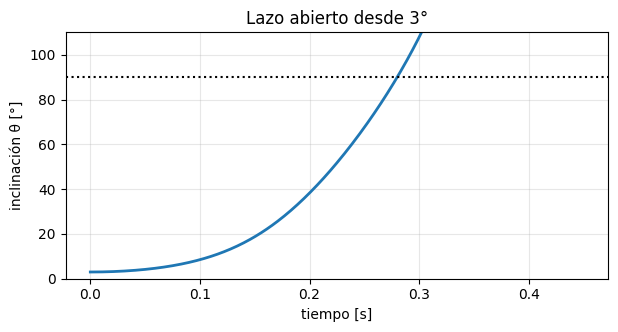

In [6]:
def f_nolineal(s, tau=0.0, Mb=Mb):
    """s = [x, xdot, th, thdot]  ->  derivada del estado."""
    A, B, C, _ = coeficientes(Mb=Mb)        # Obtiene parámetros
    x, xd, th, thd = s                      # Desempaqueta el vector de estado
    ct, st = np.cos(th), np.sin(th)         # Calcula coseno y seno
    M = np.array([[A,    B*ct],             # Construye matriz de inercia
                  [B*ct, C   ]])
    b = np.array([tau/r + B*st*thd**2,      # Construye vector de fuerzas ext
                  -tau  + B*G*st])
    xdd, thdd = np.linalg.solve(M, b)       # Resuelve el sistema de EcuLineal
    return np.array([xd, xdd, thd, thdd])

def rk4(f, s0, t, **kw):                            # Parámetros de entrada: f=f_nolineal , s0=estado inicial, t=instantes de tiempo, **kw=argumentos extra
    s = np.zeros((len(t), len(s0))); s[0] = s0      # Prepara matriz para guardar estados del robot
    for k in range(len(t)-1):                       # Avance paso a paso
        h = t[k+1] - t[k]                           # Calcula tamaño del paso de tiempo actual
        k1 = f(s[k],          **kw)                 # Evalúa la derivada del vector de estado actual y subpasos
        k2 = f(s[k] + h/2*k1, **kw)
        k3 = f(s[k] + h/2*k2, **kw)
        k4 = f(s[k] + h*k3,   **kw)
        s[k+1] = s[k] + h/6*(k1 + 2*k2 + 2*k3 + k4) # Calcula el estado del robot en el siguiente instante de tiempo
    return s

# Vector de tiempo para la simulación | Deste 0->0.45 con 451 puntos
t = np.linspace(0, 0.45, 451)

''' Explicación de 's':
Ejecuta la simulación con las funciones rk4 y f_nolineal.
Argumentos:
- f_nolineal = que contiene el modelo del robot.
- [0, 0, np.radians(3), 0] = es el vector del estado inicial. Posición 0. Velocidad 0. Ángulo de 3 grados (en radianes). Velocidad angular 0.
- t = vector de tiempo.
'''
s = rk4(f_nolineal, [0, 0, np.radians(3), 0], t)

# Gráfico
plt.figure(figsize=(7, 3.2))
plt.plot(t, np.degrees(s[:, 2]), lw=2)                 # Curva azul de ángulo del robot según simulación
plt.axhline(90, ls=":", color="k")                     # Línea negra que indica 90º = robot cae al suelo
plt.xlabel("tiempo [s]"); plt.ylabel("inclinación θ [°]"); plt.ylim(0, 110)
plt.title("Lazo abierto desde 3°"); plt.grid(alpha=.3); plt.show()


### Paso 1 · Tiempo de caída

Complete la función. `t_caida` debe devolver el instante en el que θ llega a 90°, es decir, cuando
el robot ya está acostado.

In [7]:
def t_caida(th0_grados, Mb=Mb, t_max=1.0):
    t = np.linspace(0, t_max, 2001)
    s = rk4(f_nolineal, [0, 0, np.radians(th0_grados), 0], t, Mb=Mb)
    th = np.degrees(s[:, 2])
    # TODO: el primer instante de t en el que th supera 90 grados.
    #       Pista: np.argmax(th > 90) devuelve el índice del primer True.
    #K=...
    k = np.argmax(th > 90)
    return t[k]

# Pruebe para diferentes ángulos iniciales
for th0 in [1, 3, 5, 35, 45, 89]:
    print(f"θ0 = {th0}°  ->  cae en {1000*t_caida(th0):.0f} ms")

θ0 = 1°  ->  cae en 344 ms
θ0 = 3°  ->  cae en 280 ms
θ0 = 5°  ->  cae en 251 ms
θ0 = 35°  ->  cae en 142 ms
θ0 = 45°  ->  cae en 126 ms
θ0 = 89°  ->  cae en 18 ms


---
## 2. El modelo linealizado

Alrededor de θ = 0, con θ pequeño y θ̇ ≈ 0, se toma sen θ ≈ θ, cos θ ≈ 1 y θ̇² ≈ 0. El sistema queda

$$\begin{bmatrix} A & B \\ B & C\end{bmatrix}
\begin{bmatrix}\ddot{x}\\ \ddot{\theta}\end{bmatrix}
= \begin{bmatrix}\tau/r \\ Bg\theta - \tau\end{bmatrix}$$

y despejando se llega al espacio de estados con $\mathbf{x} = [x,\ \dot{x},\ \theta,\ \dot{\theta}]^T$
y $u = \tau$.

### Paso 2 · Complete la matriz de estado

Los dos huecos son los términos que multiplican a θ en las filas de ẍ y de θ̈. Salen de resolver
el sistema de arriba con τ = 0, usando D = AC − B².

In [8]:
def espacio_estados(Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    Am = np.array([[0, 1, 0,   0],
                   [0, 0, -(B**2 * G) / D, 0],    # Coeficiente de θ en la fila de ẍ
                   [0, 0, 0,   1],
                   [0, 0, (A * B * G) / D, 0]])   # Coeficiente de θ en la fila de θ̈
    Bm = np.array([0.0, (C/r + B)/D, 0.0, -(A + B/r)/D])
    return Am, Bm

Am, Bm = espacio_estados()
print("A =\n", np.round(Am, 3))
print("\nB =", np.round(Bm, 2))
print("\nvalores propios:", np.round(np.linalg.eigvals(Am), 3))

A =
 [[  0.      1.      0.      0.   ]
 [  0.      0.    -18.029   0.   ]
 [  0.      0.      0.      1.   ]
 [  0.      0.    293.805   0.   ]]

B = [    0.     134.58     0.   -1628.81]

valores propios: [  0.      0.     17.141 -17.141]


### Explicación del Cálculo de los Coeficientes de la Matriz $A_m$

Para completar los términos de la matriz de estado que multiplican a $\theta$ en las filas de $\ddot{x}$ y $\ddot{\theta}$, partimos del sistema linealizado en lazo abierto (sin par de entrada, $\tau = 0$):

$$\begin{bmatrix} A & B \\ B & C \end{bmatrix} \begin{bmatrix} \ddot{x} \\ \ddot{\theta} \end{bmatrix} = \begin{bmatrix} 0 \\ B g \theta \end{bmatrix}$$

Definimos el determinante del sistema como $D = A C - B^2$. Aplicando la **Regla de Cramer** para resolver el sistema lineal de ecuaciones:

1. **Para obtener $\ddot{x}$ (coeficiente de la segunda fila):**
   $$\ddot{x} = \frac{\det \begin{bmatrix} 0 & B \\ B g \theta & C \end{bmatrix}}{D} = \frac{0\cdot C - B(B g \theta)}{D} = \frac{-B^2 g}{D} \theta$$
   Por lo tanto, el coeficiente correspondiente en la matriz de estado (posición `[1, 2]`) es:
   $$\mathbf{A_m[1, 2] = -\frac{B^2 g}{D}}$$

2. **Para obtener $\ddot{\theta}$ (coeficiente de la cuarta fila):**
   $$\ddot{\theta} = \frac{\det \begin{bmatrix} A & 0 \\ B & B g \theta \end{bmatrix}}{D} = \frac{A(B g \theta) - 0 \cdot B}{D} = \frac{A B g}{D} \theta$$
   Por lo tanto, el coeficiente correspondiente en la matriz de estado (posición `[3, 2]`) es:
   $$\mathbf{A_m[3, 2] = \frac{A B g}{D}}$$

### Paso 3 · El polo inestable y el periodo de muestreo

El valor propio positivo `p` es el que hace caer al robot. Su inverso `1/p` es la constante de
tiempo de la caída.

Regla práctica de control digital: el lazo debe muestrear al menos **20 veces** dentro de una
constante de tiempo del modo más rápido de la planta.

In [10]:
p = max(np.linalg.eigvals(Am).real)
print(f"polo inestable        p    = +{p:.3f} rad/s")
print(f"constante de tiempo   1/p  = {1000/p:.1f} ms")

# periodo de muestreo máximo admisible, en milisegundos (al menos 20 veces dentro de la constante de tiempo)
Ts_ms = (1000 / p) / 20
print(f"periodo de muestreo   Ts  <= {Ts_ms:.2f} ms")

polo inestable        p    = +17.141 rad/s
constante de tiempo   1/p  = 58.3 ms
periodo de muestreo   Ts  <= 2.92 ms


---
## 3. ¿Hasta dónde sirve la linealización?

Con τ = 0 y θ̇ = 0, los dos modelos predicen aceleraciones angulares distintas:

$$\ddot{\theta}_{\text{no lineal}} = \frac{ABg\sin\theta}{AC - B^2\cos^2\theta}
\qquad
\ddot{\theta}_{\text{lineal}} = \frac{ABg\,\theta}{D}$$

### Paso 4 · Mida el error

In [ ]:
def thdd_nolineal(th, Mb=Mb):
    A, B, C, _ = coeficientes(Mb=Mb)
    return A*B*G*np.sin(th) / (A*C - B**2*np.cos(th)**2)

def thdd_lineal(th, Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    return A*B*G*th / D

def error_pct(th_grados):
    th = np.radians(th_grados)
    return 100*(thdd_lineal(th) - thdd_nolineal(th))/thdd_nolineal(th)

for d in [1, 2, 5, 10, 15, 20, 30, 45]:
    print(f"θ = {d:3d}°   error = {error_pct(d):6.2f} %")

θ =   1°   error =   0.06 %
θ =   2°   error =   0.24 %
θ =   5°   error =   1.52 %
θ =  10°   error =   6.08 %
θ =  15°   error =  13.60 %
θ =  20°   error =  24.00 %
θ =  30°   error =  52.83 %
θ =  45°   error = 113.14 %


5 %  de error a los 9.1°
10 % de error a los 12.9°


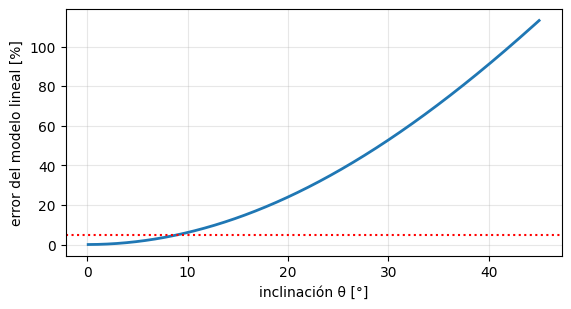

In [ ]:
# Barrido: ¿en qué ángulo el error llega al 5 %?

d = np.linspace(0.1, 45, 900)
e = np.array([error_pct(x) for x in d])
print(f"5 %  de error a los {d[np.argmax(e > 5)]:.1f}°")
print(f"10 % de error a los {d[np.argmax(e > 10)]:.1f}°")

plt.figure(figsize=(6.4, 3.2))
plt.plot(d, e, lw=2); plt.axhline(5, ls=":", color="r")
plt.xlabel("inclinación θ [°]"); plt.ylabel("error del modelo lineal [%]")
plt.grid(alpha=.3); plt.show()

---
## 4. Cambie el robot y cambia el modelo

El día de la competencia el robot puede que cambie la masa por agregados y mejoras en el diseño mecánico y estructural. Analice qué efecto tiene esto.

In [ ]:
for carga in [0.0, 0.15, 0.30, 0.60]:
    Am_c, _ = espacio_estados(Mb=Mb + carga)
    p_c = max(np.linalg.eigvals(Am_c).real)
    print(f"carga +{1000*carga:4.0f} g   ->   p = {p_c:6.3f} rad/s   "
          f"1/p = {1000/p_c:5.1f} ms   caída desde 3° = {1000*t_caida(3, Mb=Mb+carga):.0f} ms")

carga +   0 g   ->   p = 17.141 rad/s   1/p =  58.3 ms   caída desde 3° = 280 ms
carga + 150 g   ->   p = 18.819 rad/s   1/p =  53.1 ms   caída desde 3° = 262 ms
carga + 300 g   ->   p = 20.356 rad/s   1/p =  49.1 ms   caída desde 3° = 249 ms
carga + 600 g   ->   p = 23.120 rad/s   1/p =  43.3 ms   caída desde 3° = 230 ms


---
## 5. Tabla de resultados

Diligencie la tabla con los números que obtuvo. Este es el entregable de la sesión.

| Magnitud | Valor | Unidad |
|---|---|---|
| Tiempo de caída desde θ₀ = 3°, robot vacío | 280 | ms |
| Polo inestable p, robot vacío | 17.141 | rad/s |
| Periodo de muestreo máximo Ts | 2.92 | ms |
| Ángulo con 5 % de error del modelo lineal | 9.1 | ° |
| Polo inestable p con 300 g de carga | 20.356 | rad/s |

---
## 6. Tres preguntas

Responda en dos o tres frases cada una.

**6.1** El ESP32-S3 corre a 240 MHz. Con el periodo de muestreo que calculó, ¿cuántos ciclos de reloj
tiene el microcontrolador para leer la IMU, estimar el ángulo, calcular el control y escribir el PWM?
¿Le parece suficiente o está "apretado" o "corta" esa frecuencia?

**6.2** El controlador PID (o LQR en próxima clase) que van a diseñar en la se calcula a partir del modelo
**lineal**. Según lo que midió en el paso 4, ¿en qué rango de inclinación puede confiar en ese
controlador? ¿Qué pasa si el robot recibe un golpe que lo saca de ese rango?

**6.3** Los valores de `Mb`, `l` e `Ib` que aparecen al principio son estimados y generales. Debe actualizarlos con los de su propio robot. Registre acá cómo los calculó o los obtuvo.

**6.1** Con un periodo de muestreo máximo de $Ts \approx 2.92$ ms y el microcontrolador operando a 240 MHz, disponemos de aproximadamente 700,800 ciclos de reloj por ciclo de control. Esto es sumamente abundante para realizar las lecturas de la IMU mediante I2C/SPI, ejecutar filtros de estimación y calcular el algoritmo PID o LQR, por lo que la frecuencia del microcontrolador es más que suficiente y no se encuentra ajustada.

**6.2** Podemos confiar en el controlador lineal en un rango de inclinación de máximo $\pm 9.1^\circ$ (donde el error del modelo lineal se mantiene inferior al 5 %). Si un golpe saca al robot de este rango, el error del modelo lineal crece de forma no lineal rápidamente (superando el 100 % a los $45^\circ$), lo que provocará que la acción de control calculada sea insuficiente o inadecuada, llevando inevitablemente a la pérdida de estabilidad y a la caída del robot.

**6.3** Obtuvimos la masa $Mb = 0.675$ kg pesando el chasis completo junto a la electrónica y baterías en una báscula. Estimamos la distancia $l = 0.075$ m determinando físicamente el punto de equilibrio (centro de masa) del cuerpo apoyado sobre un pivote. Finalmente, calculamos $Ib = 1.406 \times 10^{-3}$ kg·m² modelando geométricamente el cuerpo del robot como un prisma rectangular homogéneo.

---
## Criterios de éxito

La actividad está lograda si al terminar la sesión su equipo puede:

1. Ejecutar el cuaderno completo sin errores.
2. Justificar de dónde sale cada uno de los dos coeficientes que completó en la matriz de estado.
3. Justificar por qué el periodo de muestreo del balancín no puede ser de 50 ms.
4. Nombrar el rango de inclinación en el que el modelo lineal es utilizable y decir qué observó
   fuera de ese rango.
5. Explicar por qué añadir carga al cuerpo cambia el polo inestable.

---
*Control Inteligente II – Ing. Jeisson Martínez Flórez*